In [91]:
import pandas as pd
import os

In [92]:
all_files = sorted(os.listdir("my_spotify_data"))

Streaming_History_Audio_2019.json


In [93]:
path = "my_spotify_data/"

df_list = []

for file in audio_files:
    df = pd.read_json(path + file)
    df_list.append(df)

df = pd.concat(df_list, ignore_index=True)

In [94]:
df

,ts,platform,ms_played,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,episode_name,episode_show_name,spotify_episode_uri,...,audiobook_uri,audiobook_chapter_uri,audiobook_chapter_title,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode
0,2019-05-12T18:20:20Z,"iOS 12.1.4 (iPhone9,3)",136548,None,None,None,None,"#368: Amanda Palmer on Creativity, Pain, and Art",The Tim Ferriss Show,spotify:episode:2D9upkS6QkleX38p7z7QbC,...,NaN,NaN,NaN,clickrow,endplay,False,False,False,NaN,False
1,2019-05-12T18:23:36Z,"iOS 12.1.4 (iPhone9,3)",195855,gogobebe,MAMAMOO,White Wind,spotify:track:6E7jAJN2e3znSHyPCdQqx8,None,None,None,...,NaN,NaN,NaN,playbtn,trackdone,False,False,False,NaN,False
2,2019-05-12T18:24:18Z,"iOS 12.1.4 (iPhone9,3)",40580,"雪の華 / JISOO - LIVE BLACKPINK ARENA TOUR 2018 ""...",BLACKPINK,"BLACKPINK ARENA TOUR 2018 ""SPECIAL FINAL IN KY...",spotify:track:1sIKkwYIffUw0vLU8RsWIR,None,None,None,...,NaN,NaN,NaN,trackdone,fwdbtn,False,False,False,NaN,False
3,2019-05-12T18:29:14Z,"iOS 12.1.4 (iPhone9,3)",296476,Mermaid,BOL4,Puberty BookⅠ Bom,spotify:track:35Hag1i7PY2FFTvflTUUr8,None,None,None,...,NaN,NaN,NaN,fwdbtn,trackdone,False,False,False,NaN,False
4,2019-05-12T18:29:29Z,"iOS 12.1.4 (iPhone9,3)",12730,Will Last Forever,AKMU,WINTER,spotify:track:1EoGGZ9poXAPhP6jYxwynU,None,None,None,...,NaN,NaN,NaN,trackdone,fwdbtn,False,False,False,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104807,2026-10-07T18:21:28Z,osx,6241,VÙNG XÁM,Anh Trai Vượt Ngàn Chông Gai,CÔNG DIỄN 4,spotify:track:3DAo9O8MsT04Pwb7DNg7ls,None,None,None,...,None,None,None,trackdone,endplay,True,True,False,1.791397e+09,False
104808,2026-10-07T18:23:42Z,ios,6240,Khế Ước,The Flob,TRỜI ĐÁNH TRÁNH TA - TA VA TRÚNG NGƯỜI,spotify:track:6mGcGybclF4U7CmUWxF1QI,None,None,None,...,None,None,None,trackdone,remote,False,False,False,1.791397e+09,False
104809,2026-10-07T18:23:44Z,osx,133728,60 NĂM CUỘC ĐỜI,Anh Trai Vượt Ngàn Chông Gai,CHUNG KẾT,spotify:track:5ox8278BuLaPHwbxlVWBZZ,None,None,None,...,None,None,None,clickrow,remote,True,False,False,1.791397e+09,False
104810,2026-10-07T18:23:52Z,ios,3850,60 NĂM CUỘC ĐỜI,Anh Trai Vượt Ngàn Chông Gai,CHUNG KẾT,spotify:track:5ox8278BuLaPHwbxlVWBZZ,None,None,None,...,None,None,None,remote,remote,True,False,False,1.791397e+09,False


Features to keep:
- date and time (ts)
- platform
- how many milliseconds the track was played (ms_played)
- name of the track
- name of the artists
- name of the album
- reason to start (reason_start)
- reason to end (reason_end)
- shuffle mode
- skipped
- offline mode

In [95]:
df = df [["ts", "platform", "ms_played", "master_metadata_track_name", "master_metadata_album_artist_name", 
  "master_metadata_album_album_name", "spotify_track_uri", "reason_start", "reason_end", "shuffle", "skipped", "offline"]]

In [96]:
df = df.rename(columns={"master_metadata_track_name":"track_name", 
                   "master_metadata_album_artist_name":"artist",
                   "master_metadata_album_album_name":"album"})

In [97]:
# Transform timestamp to datetime format
df["ts"] = pd.to_datetime(df["ts"], utc=True)
# Create new date and time columns
df["date"] = df["ts"].dt.date
df["time"] = df["ts"].dt.hour
# Create a new column for time of the day
time_bins = [-1, 4, 11, 16, 20, 23]
time_label = ["Night", "Morning", "Afternoon", "Evening", "Night"]
df["time_of_day"] = pd.cut(df["time"], bins=time_bins, labels=time_label, ordered=False)

In [114]:
# Create new column device
df["device"] = "Unknown"
df.loc[df["platform"].str.contains("iphone|ios|ipad", case=False), "device"] = "phone/tablet"
df.loc[df["platform"].str.contains("window|desktop|os x|osx|web_player", case=False), "device"] = "laptop/computer"
df.loc[df["platform"].str.contains("chromecast|cast", case=False), "device"] = "tv"
df.loc[df["device"] == "Unknown", "device"] = "others"

In [100]:
# Create a new column to calculate listening duration (in minutes)
df["minutes"] = round(df["ms_played"]/60000,2)

### EDA

In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104812 entries, 0 to 104811
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   ts                 104812 non-null  datetime64[ns, UTC]
 1   platform           104812 non-null  object             
 2   ms_played          104812 non-null  int64              
 3   track_name         101794 non-null  object             
 4   artist             101794 non-null  object             
 5   album              101794 non-null  object             
 6   spotify_track_uri  101794 non-null  object             
 7   reason_start       104812 non-null  object             
 8   reason_end         104812 non-null  object             
 9   shuffle            104812 non-null  bool               
 10  skipped            104812 non-null  bool               
 11  offline            104812 non-null  bool               
 12  date               104812 non-

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

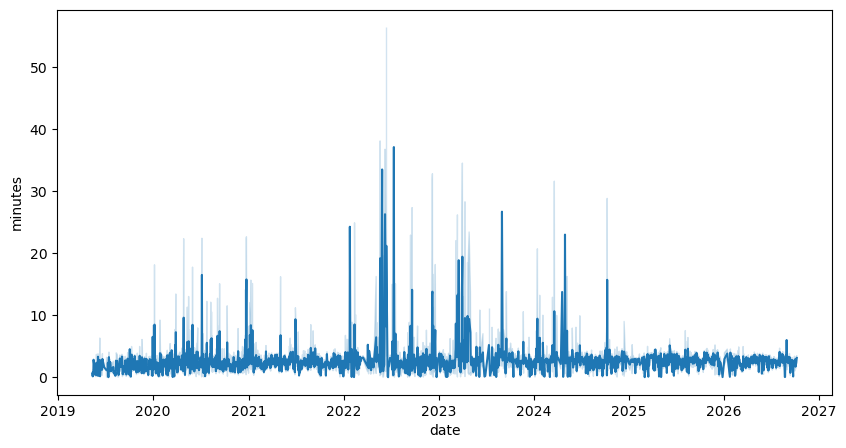

In [72]:
# Plot listening history
plt.figure(figsize=(10,5))
sns.lineplot(x="date", y="minutes", data=df)
plt.show()

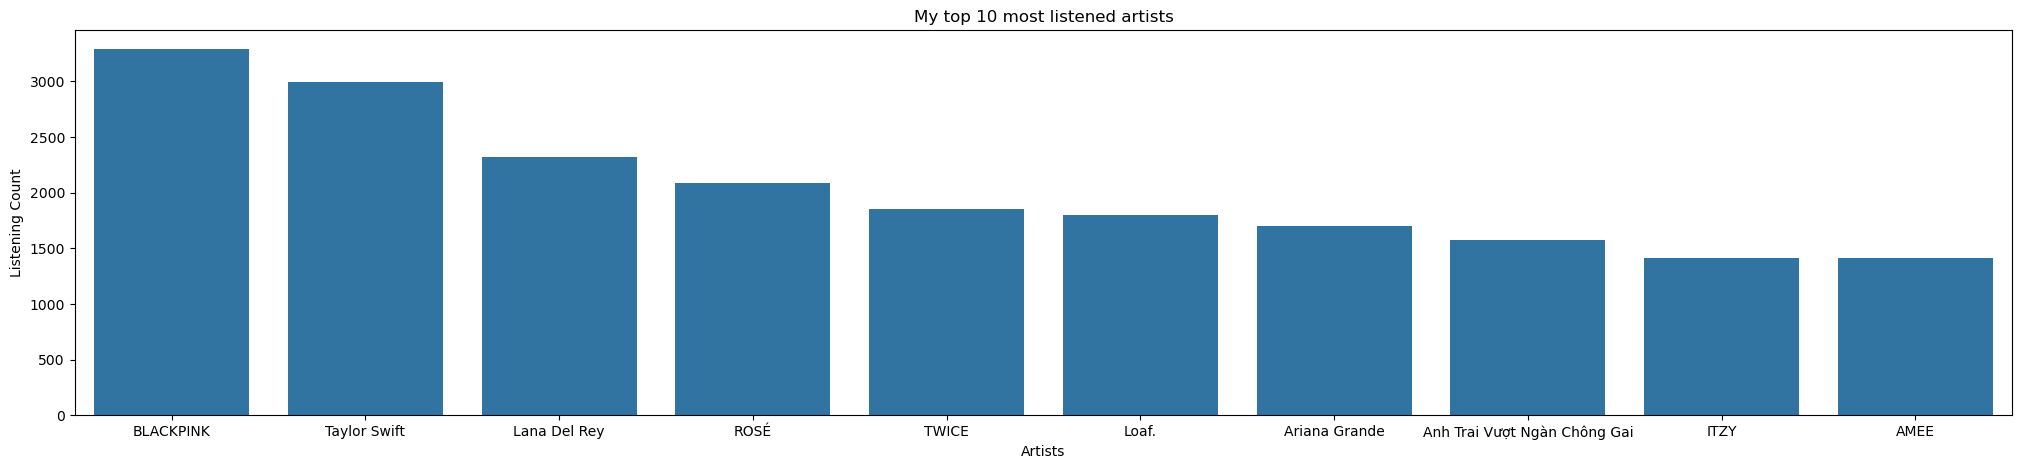

In [104]:
# Top 10 artists (based on number of times listening to the artists)
artist_analysis = df.groupby("artist")["spotify_track_uri"].count()
top_artist = artist_analysis.sort_values(ascending=False)[:10]

plt.figure(figsize=(25,5))
sns.barplot(top_artist)
plt.xlabel("Artists")
plt.ylabel("Listening Count")
plt.title("My top 10 most listened artists")
plt.show()

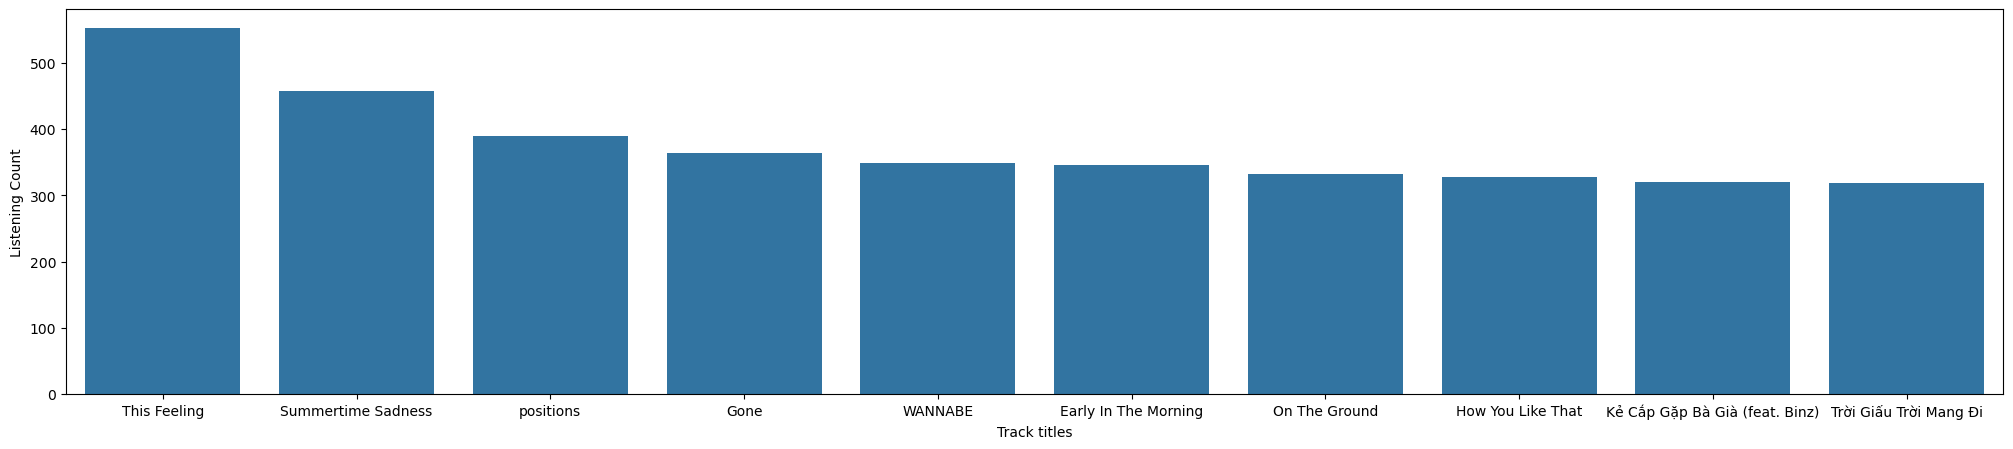

In [107]:
# Top 10 songs (based on number of times listening to the songs)
song_analysis = df.groupby("track_name")["spotify_track_uri"].count()

top_song = song_analysis.sort_values(ascending=False)[:10]

plt.figure(figsize=(25,5))
sns.barplot(top_song)
plt.xlabel("Track titles")
plt.ylabel("Listening Count")
plt.show()

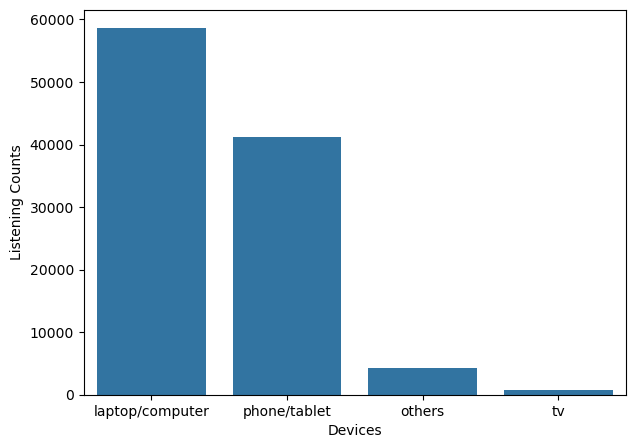

In [124]:
# Most used devices
device_analysis = df["device"].value_counts()

plt.figure(figsize=(7,5))
sns.barplot(device_analysis)
plt.xlabel("Devices")
plt.ylabel("Listening Counts")
plt.show()

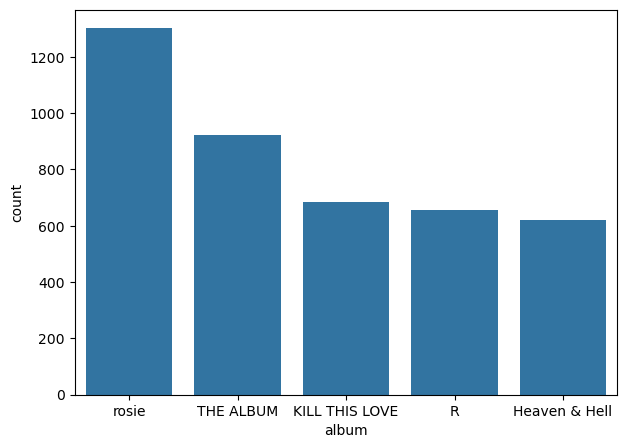

In [141]:
# Top 5 albums (based on number of times listening to the albums)
album_analysis = df["album"].value_counts()
top_album = album_analysis[:5]
plt.figure(figsize=(7,5))
sns.barplot(top_album)
plt.show()